# Weather prediction
This is for a final project of IBM time series  
Link: https://www.coursera.org/learn/time-series-survival-analysis/  

Author: Hyunyong Lee  
Date: 2026 January 12th  

**Objective**  
Predict baggage claim for airline.

**Agenda**
1) Data extraction
2) EDA
3) Time series decomposition
4) Time series modelling
5) Survival analysis of selling timing
6) Discussion


In [74]:
# Import libraries
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

%matplotlib inline
plotsize = (13, 5)

## 1. Data extraction  
Data source: https://www.kaggle.com/datasets/gabrielsantello/airline-baggage-complaints-time-series-dataset

In [75]:
# Data extraction
df = pd.read_csv("data/baggagecomplaints.csv")
df.head()

,Airline,Date,Month,Year,Baggage,Scheduled,Cancelled,Enplaned
0,American Eagle,01/2004,1,2004,12502,38276,2481,992360
1,American Eagle,02/2004,2,2004,8977,35762,886,1060618
2,American Eagle,03/2004,3,2004,10289,39445,1346,1227469
3,American Eagle,04/2004,4,2004,8095,38982,755,1234451
4,American Eagle,05/2004,5,2004,10618,40422,2206,1267581


In [76]:
# Preprocessing data type; date and make it as an index
df["Date"] = pd.to_datetime(df["Date"], format="%m/%Y")
df = df.set_index("Date")
df.head()

,Airline,Month,Year,Baggage,Scheduled,Cancelled,Enplaned
Date,,,,,,,
2004-01-01,American Eagle,1,2004,12502,38276,2481,992360
2004-02-01,American Eagle,2,2004,8977,35762,886,1060618
2004-03-01,American Eagle,3,2004,10289,39445,1346,1227469
2004-04-01,American Eagle,4,2004,8095,38982,755,1234451
2004-05-01,American Eagle,5,2004,10618,40422,2206,1267581


In [77]:
df["Airline"].unique()

array(['American Eagle', 'Hawaiian', 'United'], dtype=object)

In [78]:
# Describe dataframe
print("--------")
print("data frame overall")
print(df.info())
print("--------")
print("Unique value count")
print(df.nunique())
print("--------")
print("Null value rate")
print(df.isnull().sum()/len(df)*100)
print("--------")
print("Describe numerical columns")
print(df.describe())
print("--------")
print("Describe categorical columns")
print(df.describe(include=["object", "category"]))
print("--------")


--------
data frame overall
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 252 entries, 2004-01-01 to 2010-12-01
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   Airline    252 non-null    object
 1   Month      252 non-null    int64 
 2   Year       252 non-null    int64 
 3   Baggage    252 non-null    int64 
 4   Scheduled  252 non-null    int64 
 5   Cancelled  252 non-null    int64 
 6   Enplaned   252 non-null    int64 
dtypes: int64(6), object(1)
memory usage: 15.8+ KB
None
--------
Unique value count
Airline        3
Month         12
Year           7
Baggage      252
Scheduled    248
Cancelled    198
Enplaned     252
dtype: int64
--------
Null value rate
Airline      0.0
Month        0.0
Year         0.0
Baggage      0.0
Scheduled    0.0
Cancelled    0.0
Enplaned     0.0
dtype: float64
--------
Describe numerical columns
            Month        Year       Baggage     Scheduled    Cancelled  \
count  252.00

Good news! No null numbers.  
We will focus on "American Eagle". 

In [79]:
df = df[df["Airline"]=="American Eagle"]
df = df.asfreq("MS")  # set up frequency
df.head()

,Airline,Month,Year,Baggage,Scheduled,Cancelled,Enplaned
Date,,,,,,,
2004-01-01,American Eagle,1,2004,12502,38276,2481,992360
2004-02-01,American Eagle,2,2004,8977,35762,886,1060618
2004-03-01,American Eagle,3,2004,10289,39445,1346,1227469
2004-04-01,American Eagle,4,2004,8095,38982,755,1234451
2004-05-01,American Eagle,5,2004,10618,40422,2206,1267581


## 2. EDA

### 2-1. Visualization

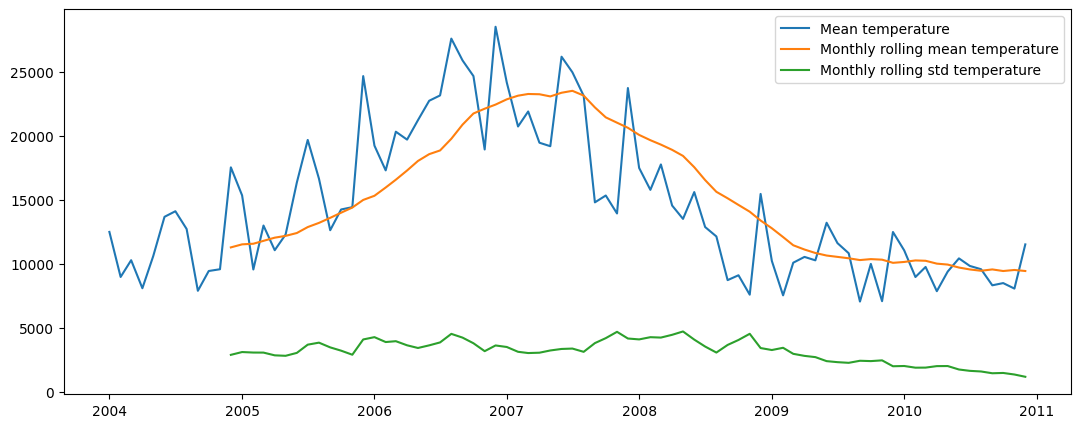

In [80]:
plt.figure(figsize=plotsize)
plt.plot(df["Baggage"], label="Mean temperature")
plt.plot(df["Baggage"].rolling(window=12).mean(), label="Monthly rolling mean temperature")
plt.plot(df["Baggage"].rolling(window=12).std(), label="Monthly rolling std temperature")
plt.legend()
plt.show()

The mean and variance of time series change by time; Maybe time series is not stationary.
Check the stationary by adf test.

In [81]:
import statsmodels.tsa.stattools as ts

dftest = ts.adfuller(df["Baggage"],)
dfoutput = pd.Series(dftest[0:4], 
                        index=['Test Statistic','p-value','Lags Used','Observations Used'])
for key,value in dftest[4].items():
    dfoutput['Critical Value (%s)'%key] = value
print(dfoutput)

Test Statistic          -2.262600
p-value                  0.184314
Lags Used               12.000000
Observations Used       71.000000
Critical Value (1%)     -3.526005
Critical Value (5%)     -2.903200
Critical Value (10%)    -2.588995
dtype: float64


p-value is > 0.05 and it suggested that the time series is not stationary.

## 3. Time series decomposition

In [82]:
# common function for acf & pacf plots
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

def plots(data, lags=None, title=None):
    layout = (3, 1)
    raw = plt.subplot2grid(layout, (0, 0))
    acf = plt.subplot2grid(layout, (1, 0))
    pacf = plt.subplot2grid(layout, (2, 0))
    
    raw.plot(data) 
    plot_acf(data, lags=lags, ax=acf, zero=False, auto_ylims=True)
    plot_pacf(data, lags=lags, ax=pacf, zero = False, auto_ylims=True)
    sns.despine()
    if title is not None:
        plt.suptitle(title)
    plt.tight_layout()
    plt.show()


# Metrics function
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    mean_absolute_percentage_error
)

def score(y_act, y_pred):
    mse = mean_squared_error(y_act, y_pred)
    mae = mean_absolute_error(y_act, y_pred)
    mape = mean_absolute_percentage_error(y_act, y_pred)

    return mse, mae, mape

Decomposition of original time series.  
Seasonality is assumed s=12 because we handle monthly data but this will be revisited with correlation analysis.  

In [83]:
from statsmodels.tsa.seasonal import seasonal_decompose

ss_decomposition = seasonal_decompose(x=df["Baggage"], model="additive", period=12)
est_trend = ss_decomposition.trend
est_seasonal = ss_decomposition.seasonal
est_residual = ss_decomposition.resid

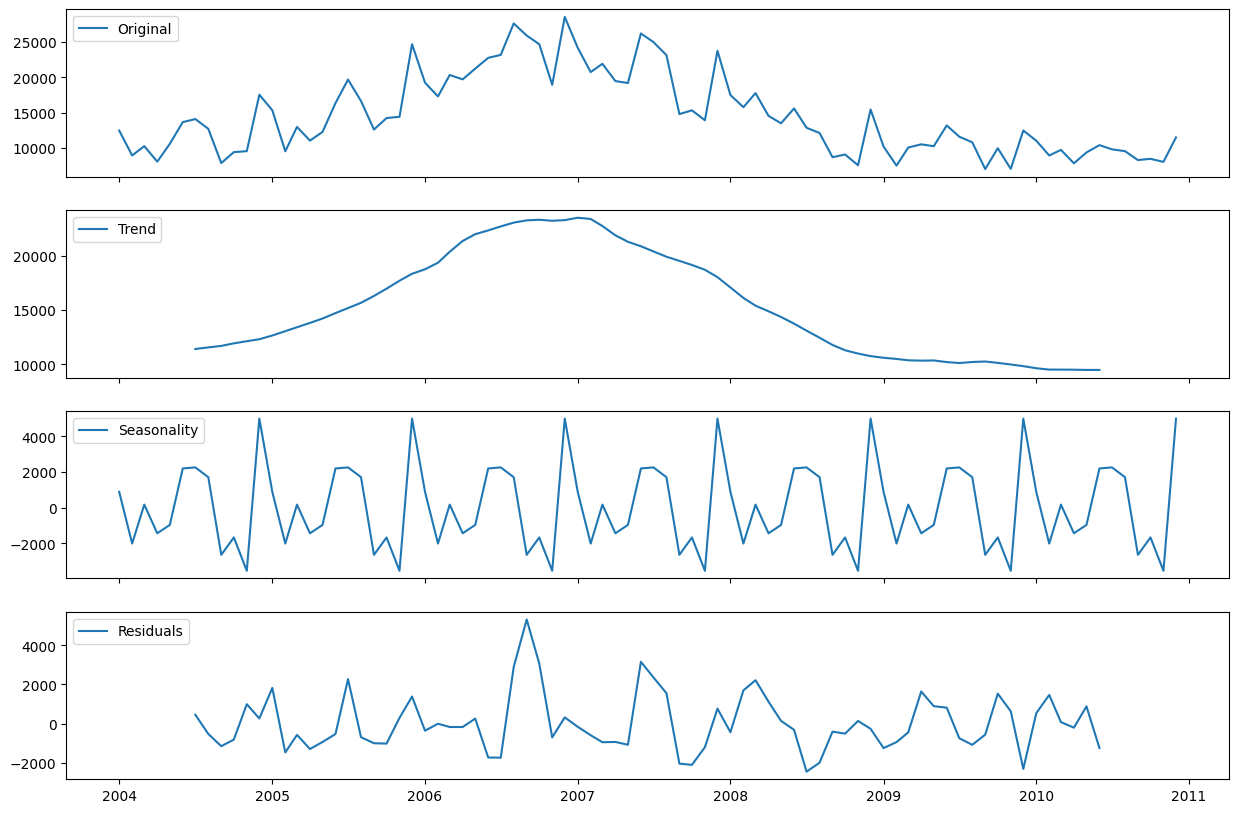

In [84]:
fig, axes = plt.subplots(4, 1, sharex=True, sharey=False)
fig.set_figheight(10)
fig.set_figwidth(15)

axes[0].plot(df["Baggage"], label='Original')
axes[0].legend(loc='upper left')

axes[1].plot(est_trend, label='Trend')
axes[1].legend(loc='upper left')

axes[2].plot(est_seasonal, label='Seasonality')
axes[2].legend(loc='upper left')

axes[3].plot(est_residual, label='Residuals')
axes[3].legend(loc='upper left')

plt.show()

There is sine wave like trend across year and we might need further analysis to check
1) Check differencing to be stationary
2) Define AR & MA terms for a model

ACF & PACF for original df


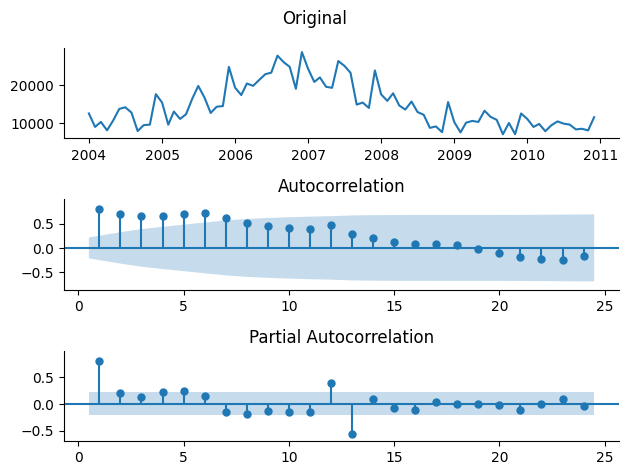

In [85]:
print("ACF & PACF for original df")
plots(df["Baggage"], 24, "Original")

PACF shows lag = 1 has significant correlation.  
We will take differencing with lag 1.

ACF & PACF for original df with lag=1


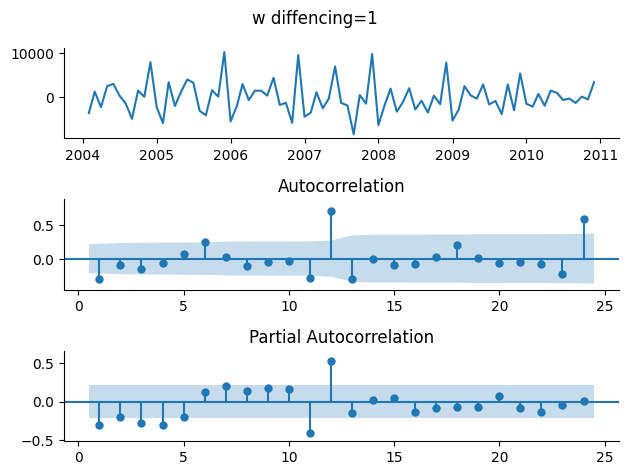

In [86]:
print("ACF & PACF for original df with lag=1")
plots(df["Baggage"].diff(1).dropna(), 24, "w diffencing=1")

In [87]:
df_lag1 = df["Baggage"] - df["Baggage"].shift(1)

dftest = ts.adfuller(df_lag1.dropna())
dfoutput = pd.Series(dftest[0:4], 
                        index=['Test Statistic','p-value','Lags Used','Observations Used'])
for key,value in dftest[4].items():
    dfoutput['Critical Value (%s)'%key] = value
dfoutput

Test Statistic          -1.402109
p-value                  0.581265
Lags Used               12.000000
Observations Used       70.000000
Critical Value (1%)     -3.527426
Critical Value (5%)     -2.903811
Critical Value (10%)    -2.589320
dtype: float64

ACF shows there might be still seasionality with lag = 12.  
adf test shows that the time series is still non-stationary with differencing 1

ACF & PACF for original df with lag=1 and another lag=12


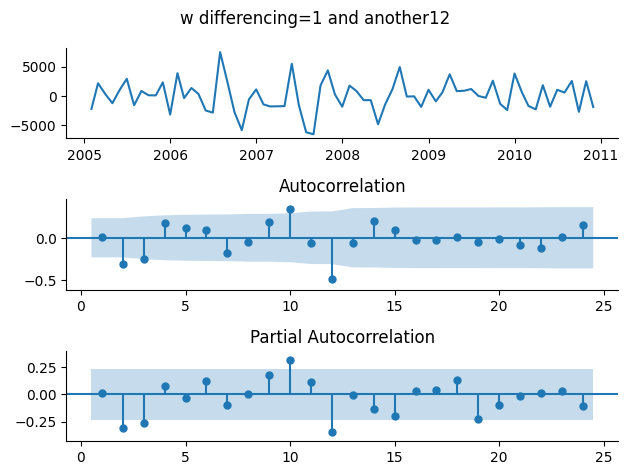

In [88]:
print("ACF & PACF for original df with lag=1 and another lag=12")
plots(df["Baggage"].diff(1).diff(12).dropna(), 24, "w differencing=1 and another12")

In [89]:
df_lag1_12 = df["Baggage"] - df["Baggage"].shift(1).shift(12)

dftest = ts.adfuller(df_lag1_12.dropna())
dfoutput = pd.Series(dftest[0:4], 
                        index=['Test Statistic','p-value','Lags Used','Observations Used'])
for key,value in dftest[4].items():
    dfoutput['Critical Value (%s)'%key] = value
dfoutput

Test Statistic          -3.226053
p-value                  0.018525
Lags Used               12.000000
Observations Used       58.000000
Critical Value (1%)     -3.548494
Critical Value (5%)     -2.912837
Critical Value (10%)    -2.594129
dtype: float64

Now time series looks stationary (p-value < 0.05).  
After differencing d=1 and D=1 with s=12, there are no significant cut-offs in ACF and PACF: (p,d,q) would be (0,1,0).  
There are spike on lag=12 (same as s=12) and no significant spikes on lag=24: (P,D,Q,s) = (1,1,1,12).  
Given that (p,d,q)(P,D,Q,s) = (0,1,0)(1,1,1,12)

In [90]:
import statsmodels.api as sm

sar = sm.tsa.statespace.SARIMAX(
    df["Baggage"], 
    order=(0,1,0), 
    seasonal_order=(1,1,1,12), 
    trend='n'
    ).fit()

sar.summary()

RUNNING THE L-BFGS-B CODE

           * * *

Machine precision = 2.220D-16
 N =            3     M =           10

At X0         0 variables are exactly at the bounds

At iterate    0    f=  7.91040D+00    |proj g|=  1.20147D-01

At iterate    5    f=  7.82748D+00    |proj g|=  1.42609D-01


 This problem is unconstrained.



At iterate   10    f=  7.78056D+00    |proj g|=  3.53985D-03

At iterate   15    f=  7.77528D+00    |proj g|=  6.78121D-04

At iterate   20    f=  7.77435D+00    |proj g|=  2.79590D-03

At iterate   25    f=  7.75473D+00    |proj g|=  6.47525D-05

           * * *

Tit   = total number of iterations
Tnf   = total number of function evaluations
Tnint = total number of segments explored during Cauchy searches
Skip  = number of BFGS updates skipped
Nact  = number of active bounds at final generalized Cauchy point
Projg = norm of the final projected gradient
F     = final function value

           * * *

   N    Tit     Tnf  Tnint  Skip  Nact     Projg        F
    3     29     33      1     0     0   8.543D-07   7.755D+00
  F =   7.7546726021684700     

CONVERGENCE: NORM_OF_PROJECTED_GRADIENT_<=_PGTOL            


<class 'statsmodels.iolib.summary.Summary'>
"""
                                      SARIMAX Results                                       
============================================================================================
Dep. Variable:                              Baggage   No. Observations:                   84
Model:             SARIMAX(0, 1, 0)x(1, 1, [1], 12)   Log Likelihood                -651.392
Date:                              Sat, 24 Jan 2026   AIC                           1308.785
Time:                                      10:59:35   BIC                           1315.573
Sample:                                  01-01-2004   HQIC                          1311.484
                                       - 12-01-2010                                         
Covariance Type:                                opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.S.L12       0.4208      0.100      4.204      0.000       0.225       0.617
ma.S.L12      -1.0000      0.149     -6.725      0.000      -1.291      -0.709
sigma2       4.53e+06   3.28e-08   1.38e+14      0.000    4.53e+06    4.53e+06
===================================================================================
Ljung-Box (L1) (Q):                   0.77   Jarque-Bera (JB):                 1.37
Prob(Q):                              0.38   Prob(JB):                         0.50
Heteroskedasticity (H):               0.34   Skew:                             0.01
Prob(H) (two-sided):                  0.01   Kurtosis:                         3.68
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
[2] Covariance matrix is singular or near-singular, with condition number 1.81e+29. Standard errors may be unstable.
"""

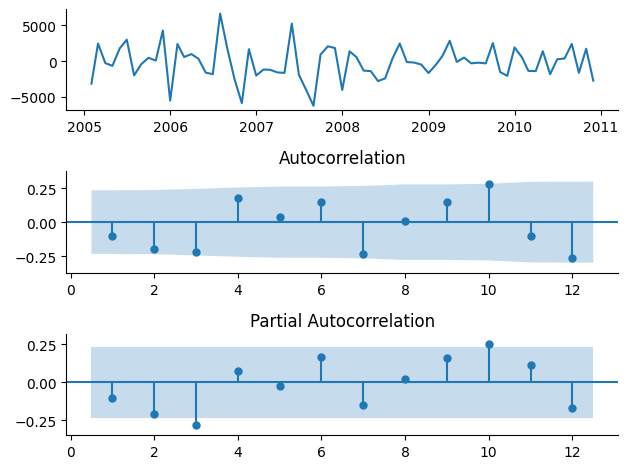

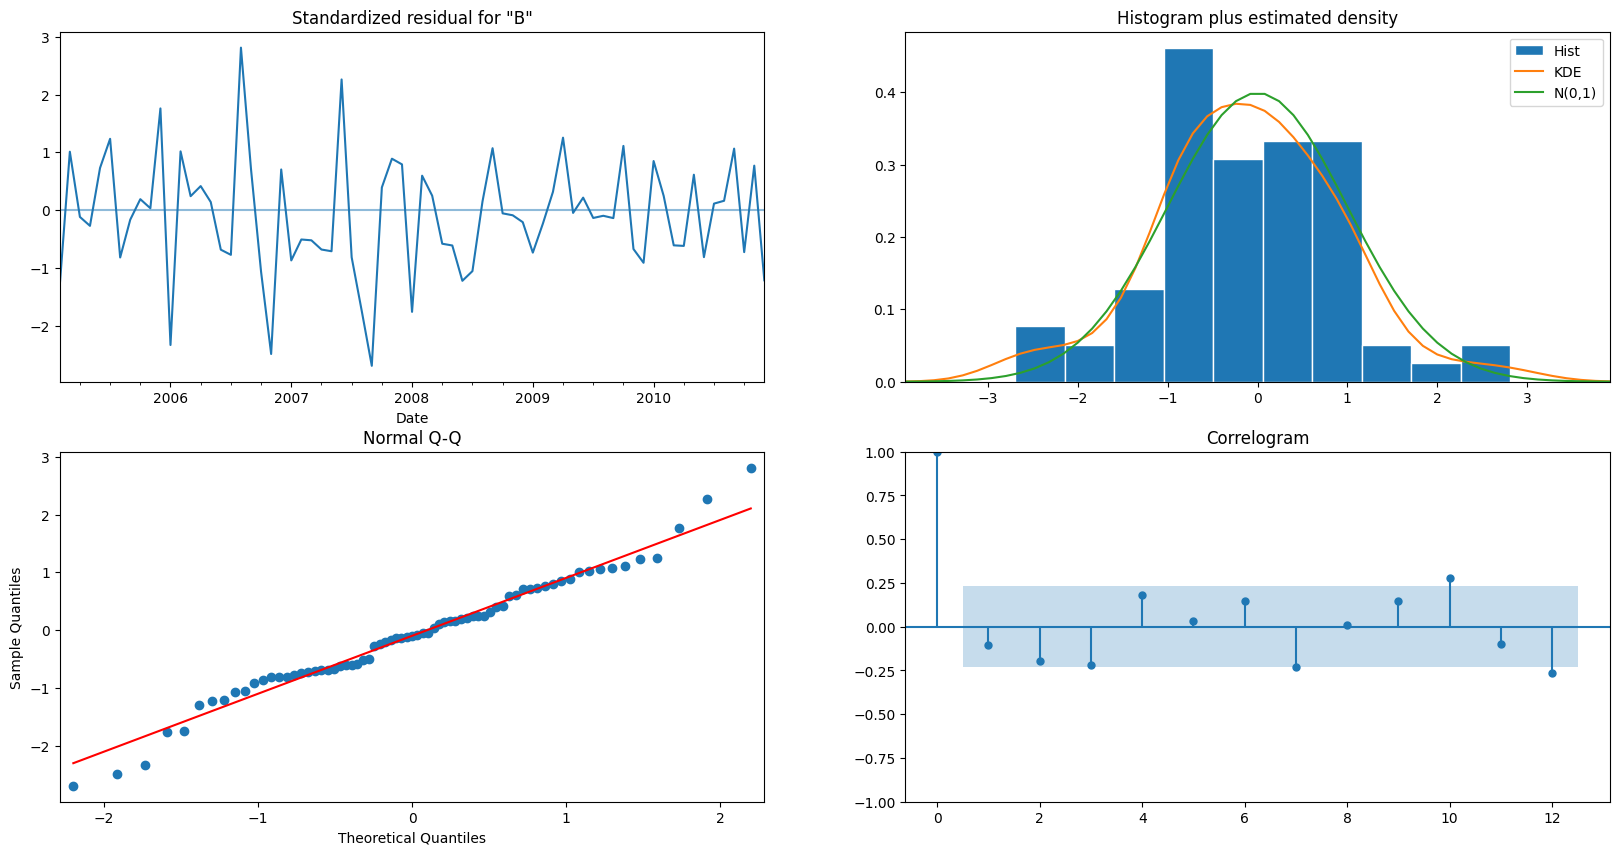

In [91]:
# plot resids & residual diagnostics
plots(sar.resid[sar.loglikelihood_burn:], lags=12)
_ = sar.plot_diagnostics(lags=12,figsize = (20,10),)

With given paramters; p,d,q, P,D,Q and m, now the time series data does not have significant correlations with certain lag and residuals is a normal distribution.  
We will proceed to create forecast by the fitted SARIMAX model with parameters estimated above.

In [92]:
# Train-test data split with given date by 2009-12-31
date = "2009-12-31"
train = df[:date]
test = df[date:]

In [93]:
# Check index for forecast horizon; start 2010-01-01 end max of date
df_idx = df.reset_index()

print(df_idx[(df_idx["Date"]=="2010-01-01") | (df_idx["Date"]==max(df_idx["Date"]))].index)

Index([72, 83], dtype='int64')


In [94]:
#use model.predict() start and end in relation to series
df['forecast_manual'] = sar.predict(start = 72, end = 83)

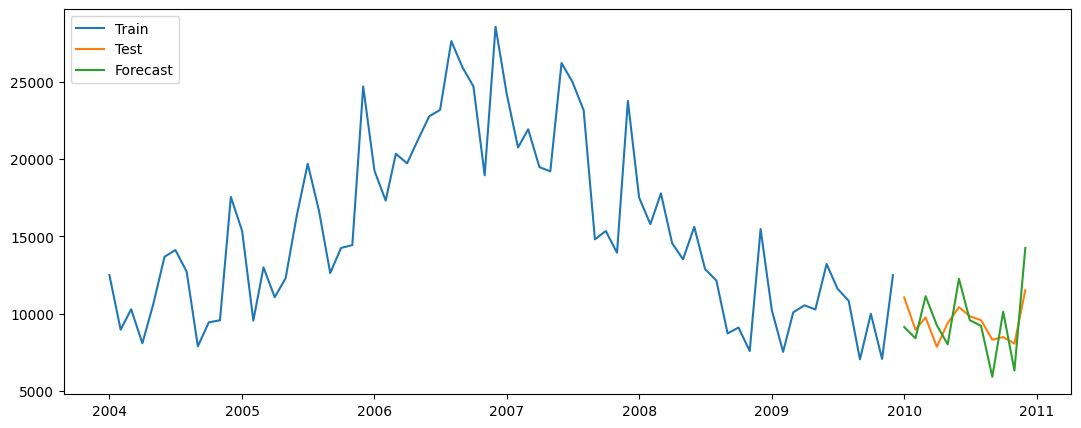

In [95]:
plt.figure(figsize=plotsize)
plt.plot(df.index[:72], df['Baggage'][:72], label="Train")
plt.plot(df.index[72:], df['Baggage'][72:], label="Test")
plt.plot(df.index, df['forecast_manual'], label="Forecast")
plt.legend(loc="upper left")
plt.show()

In [96]:
# evaluate the model
mse, mae, mape = score(df["Baggage"][-10:], df["forecast_manual"][-10:])
print("SARIMAX model evaluation with manual fitting")
print("mse:", mse)
print("mae", mae)
print("mape", mape)

SARIMAX model evaluation with manual fitting
mse: 2820750.238014421
mae 1510.1995569847516
mape 0.16372225254297365


Now we will try auto fitting of SARIMAX model.

In [97]:
import pmdarima as pm
stepwise_model = pm.auto_arima(
    train["Baggage"], start_p=3, start_q=2, max_p=3, max_q=2,
    start_P=1, start_Q=1, max_P=2, max_Q=2,
    d=1, D=1, m=12, seasonal=True,
    trace=True, error_action='ignore', suppress_warnings=True, stepwise=True
)

Performing stepwise search to minimize aic
 ARIMA(3,1,2)(1,1,1)[12]             : AIC=1095.410, Time=3.52 sec
 ARIMA(0,1,0)(0,1,0)[12]             : AIC=1101.130, Time=0.01 sec
 ARIMA(1,1,0)(1,1,0)[12]             : AIC=1098.796, Time=0.58 sec
 ARIMA(0,1,1)(0,1,1)[12]             : AIC=1097.707, Time=0.23 sec
 ARIMA(3,1,2)(0,1,1)[12]             : AIC=1097.181, Time=1.47 sec
 ARIMA(3,1,2)(1,1,0)[12]             : AIC=1097.838, Time=1.53 sec
 ARIMA(3,1,2)(2,1,1)[12]             : AIC=1097.749, Time=5.49 sec
 ARIMA(3,1,2)(1,1,2)[12]             : AIC=1097.102, Time=5.58 sec
 ARIMA(3,1,2)(0,1,0)[12]             : AIC=1098.650, Time=0.16 sec
 ARIMA(3,1,2)(0,1,2)[12]             : AIC=1094.285, Time=6.32 sec
 ARIMA(2,1,2)(0,1,2)[12]             : AIC=1096.639, Time=1.79 sec
 ARIMA(3,1,1)(0,1,2)[12]             : AIC=1091.868, Time=4.49 sec
 ARIMA(3,1,1)(0,1,1)[12]             : AIC=1095.220, Time=0.62 sec
 ARIMA(3,1,1)(1,1,2)[12]             : AIC=inf, Time=4.40 sec
 ARIMA(3,1,1)(1,1,1)[12]

Auto fitting method suggests that (p,d,q)(P,D,Q,m) = (3,1,1)(0,1,2,12).  
We will generate forecast with these paramters.

In [98]:
# Generate predictions
stepwise_forecast = stepwise_model.predict(n_periods=len(test))
df["forecast_auto"] = stepwise_forecast

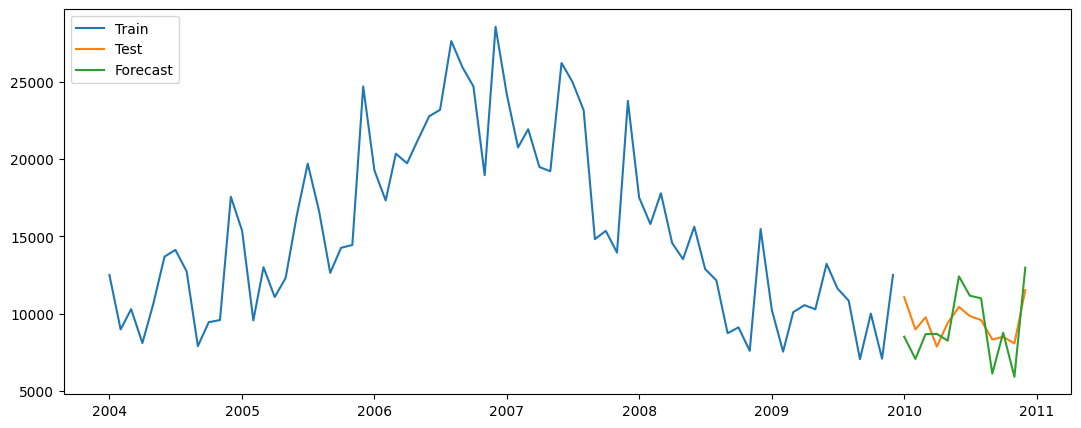

In [99]:
plt.figure(figsize=plotsize)
plt.plot(df.index[:72], df["Baggage"][:72], label="Train")
plt.plot(df.index[72:], df["Baggage"][72:], label="Test")
plt.plot(df.index, df["forecast_auto"], label="Forecast")
plt.legend(loc="upper left")
plt.show()

In [100]:
# evaluate the model
mse_stp, mae_stp, mape_stp = score(df["Baggage"][-10:], df["forecast_auto"][-10:])
print("SARIMAX with auto fitting")
print("mse:", mse_stp)
print("mae", mae_stp)
print("mape", mape_stp)


SARIMAX with auto fitting
mse: 2250262.8794175545
mae 1384.0763253228026
mape 0.14981362430314876


In [101]:
metrics = [
    {"Measure": "mse", "Manual": mse, "Auto": mse_stp, "Better score": "Manual" if abs(mse) < abs(mse_stp) else "Auto"},
    {"Measure": "mae", "Manual": mae, "Auto": mae_stp, "Better score": "Manual" if abs(mae) < abs(mae_stp) else "Auto"},
    {"Measure": "mape", "Manual": mape, "Auto": mape_stp, "Better score": "Manual" if abs(mape) < abs(mape_stp) else "Auto"},
]
metrics_df = pd.DataFrame(metrics)

metrics_df

,Measure,Manual,Auto,Better score
0,mse,2.820750e+06,2.250263e+06,Auto
1,mae,1.510200e+03,1.384076e+03,Auto
2,mape,1.637223e-01,1.498136e-01,Auto


# Discussion & Conclusion

We could apply a SARIMAX model to generate predictions with given time series.
The time series is not stationary so we need to leverge differencing to make the time series stationary.  
There were 2 approaches to create predictions; 1) Manually estimating parameters and 2) Automatically generating parameters.  
Metrics shows that the model whose parameters automatically esitmated has better performance.  
We recommand to apply SARIMAX model for forecast with automatic pamater fitting.

# Next step

1) We can try other avdanved techniques: Machine learning or Deep learning.  
2) Conduct analysis for other airlines.  
3) Understand the reason of claim and develop action plans.